In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [5]:
%pip install pandas matplotlib seaborn

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# CSV file ka path
file_name = "/content/student_performance_complete (1).csv"

# Dataset load karein
df = pd.read_csv(file_name)

# Column names clean karein
df.columns = df.columns.astype(str).str.strip()

# Numeric columns ko numeric banayein
numeric_cols = [
    "study_hours",
    "attendance_pct",
    "previous_score",
    "marks"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Missing numeric values wali rows remove karein
df = df.dropna(subset=numeric_cols)

# Dataset check karein
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset shape: (180, 7)
Columns: ['student_id', 'department', 'study_hours', 'attendance_pct', 'previous_score', 'marks', 'passed']


,student_id,department,study_hours,attendance_pct,previous_score,marks,passed
0,S001,SE,5.5,84.7,82.9,90.4,Yes
1,S002,CS,5.0,73.4,36.9,66.8,Yes
2,S003,Cybersecurity,5.8,80.5,57.8,70.9,Yes
3,S004,SE,7.8,80.5,46.1,85.4,Yes
4,S005,AI,5.6,85.8,57.3,89.6,Yes


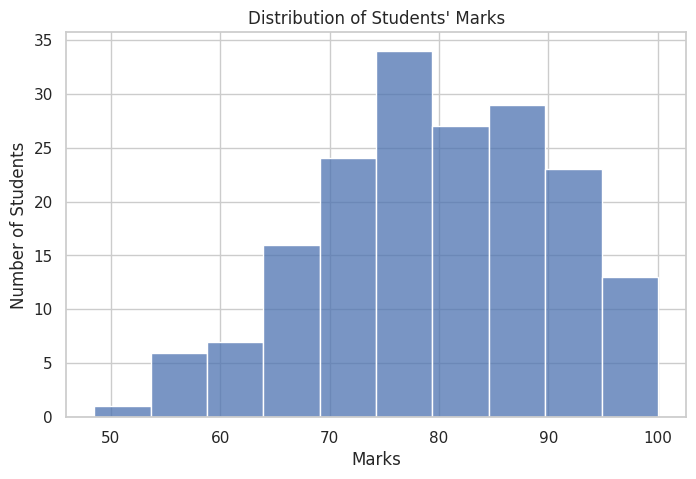

In [7]:
plt.figure()
sns.histplot(data=df, x="marks", bins=10, kde=False)

plt.title("Distribution of Students' Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()

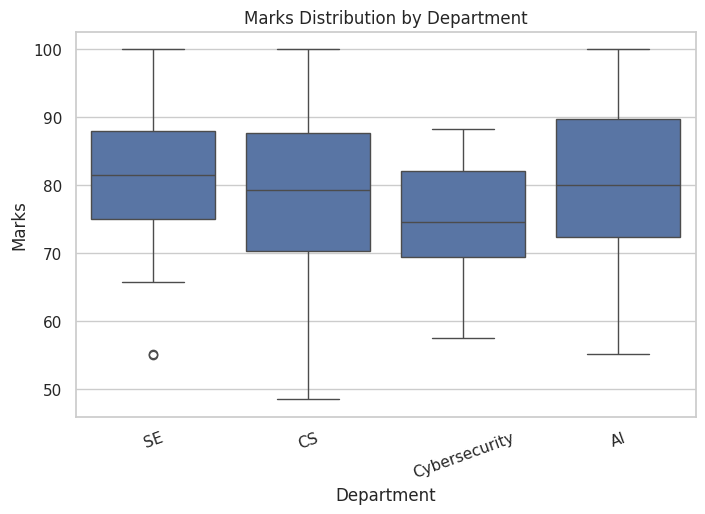

In [8]:
plt.figure()
sns.boxplot(data=df, x="department", y="marks")

plt.title("Marks Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Marks")
plt.xticks(rotation=20)
plt.show()

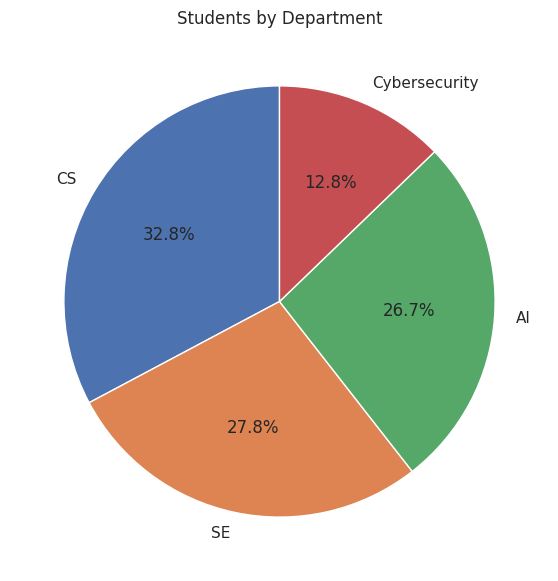

In [9]:
department_counts = df["department"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    department_counts,
    labels=department_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Students by Department")
plt.show()

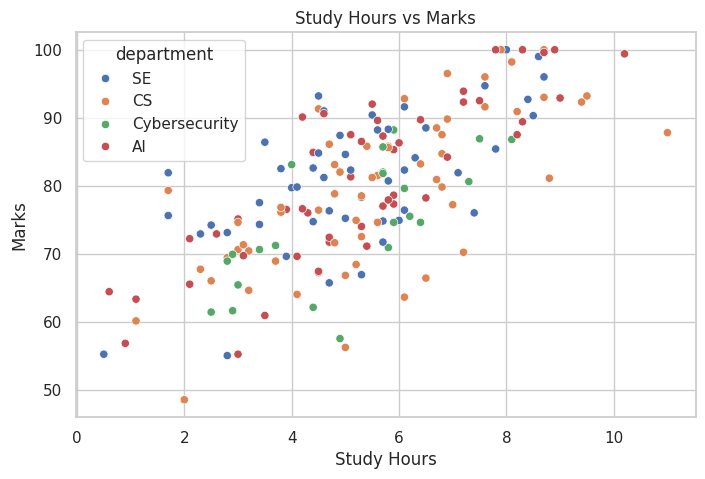

In [10]:
plt.figure()
sns.scatterplot(
    data=df,
    x="study_hours",
    y="marks",
    hue="department"
)

plt.title("Study Hours vs Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.show()

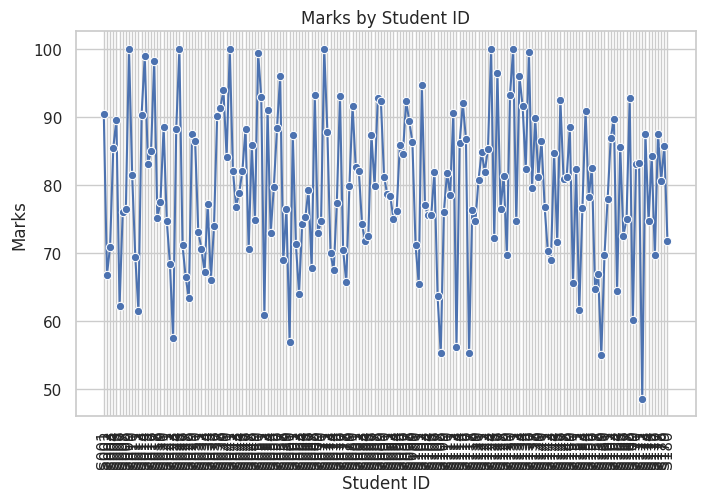

In [11]:
line_df = df.sort_values("student_id")

plt.figure()
sns.lineplot(
    data=line_df,
    x="student_id",
    y="marks",
    marker="o",
    errorbar=None
)

plt.title("Marks by Student ID")
plt.xlabel("Student ID")
plt.ylabel("Marks")
plt.xticks(rotation=90)
plt.show()

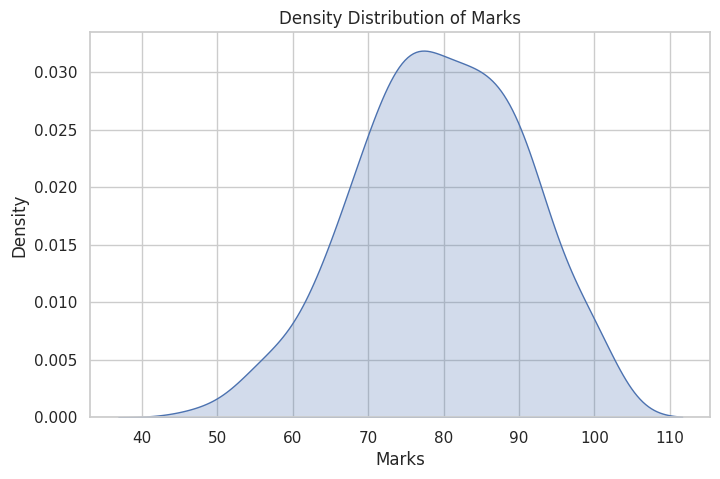

In [12]:
plt.figure()
sns.kdeplot(data=df, x="marks", fill=True)

plt.title("Density Distribution of Marks")
plt.xlabel("Marks")
plt.ylabel("Density")
plt.show()

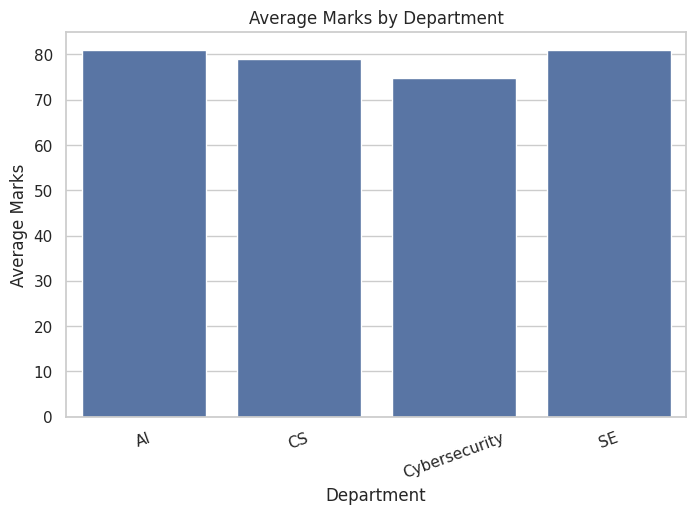

In [13]:
avg_marks = (
    df.groupby("department", as_index=False)["marks"]
    .mean()
)

plt.figure()
sns.barplot(
    data=avg_marks,
    x="department",
    y="marks"
)

plt.title("Average Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.xticks(rotation=20)
plt.show()

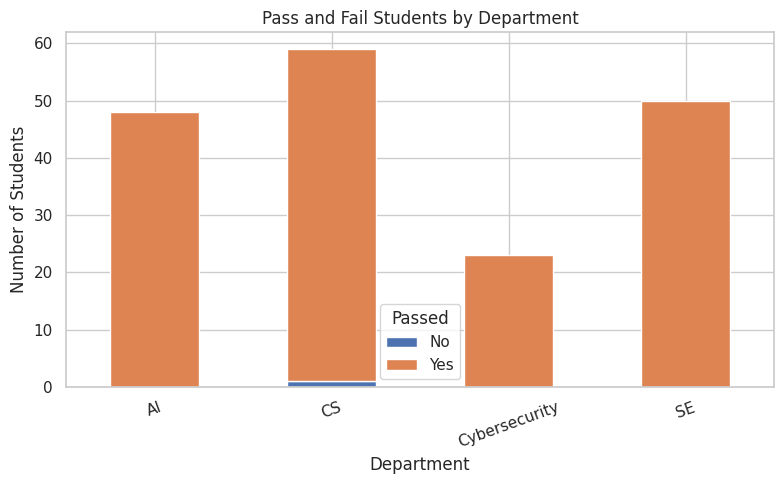

In [14]:
stacked_data = pd.crosstab(
    df["department"],
    df["passed"]
)

stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Pass and Fail Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.legend(title="Passed")
plt.tight_layout()
plt.show()

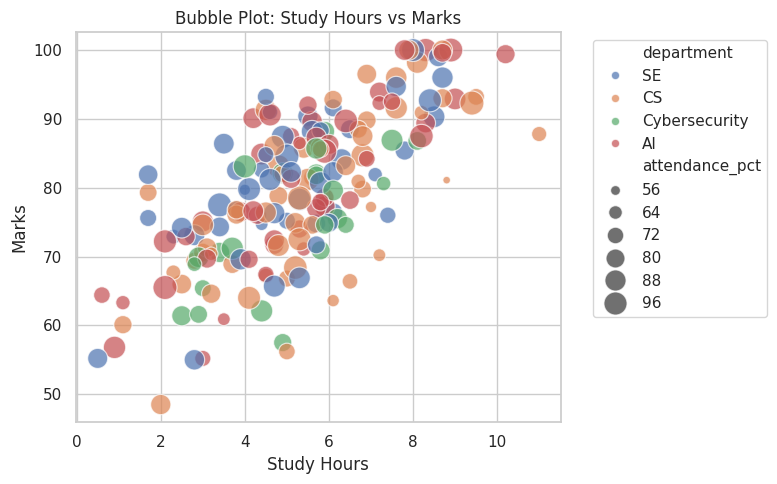

In [15]:
plt.figure()

sns.scatterplot(
    data=df,
    x="study_hours",
    y="marks",
    size="attendance_pct",
    sizes=(30, 300),
    hue="department",
    alpha=0.7
)

plt.title("Bubble Plot: Study Hours vs Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

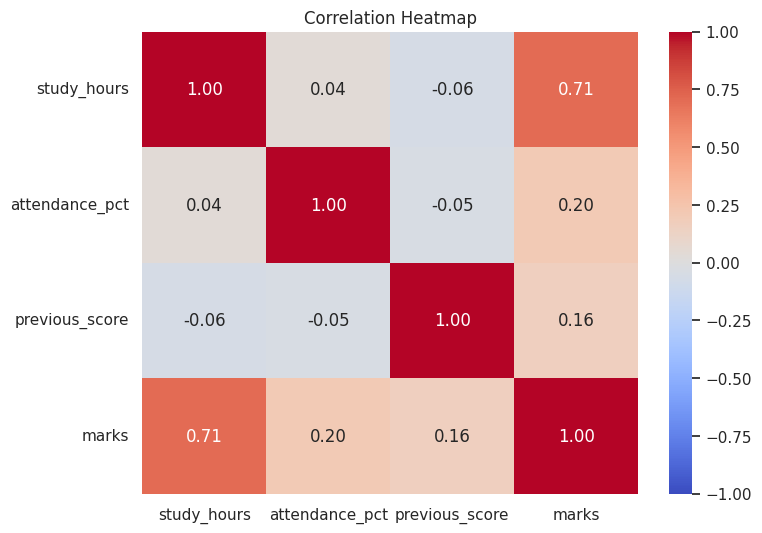

In [16]:
numeric_data = df[
    ["study_hours", "attendance_pct", "previous_score", "marks"]
]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()

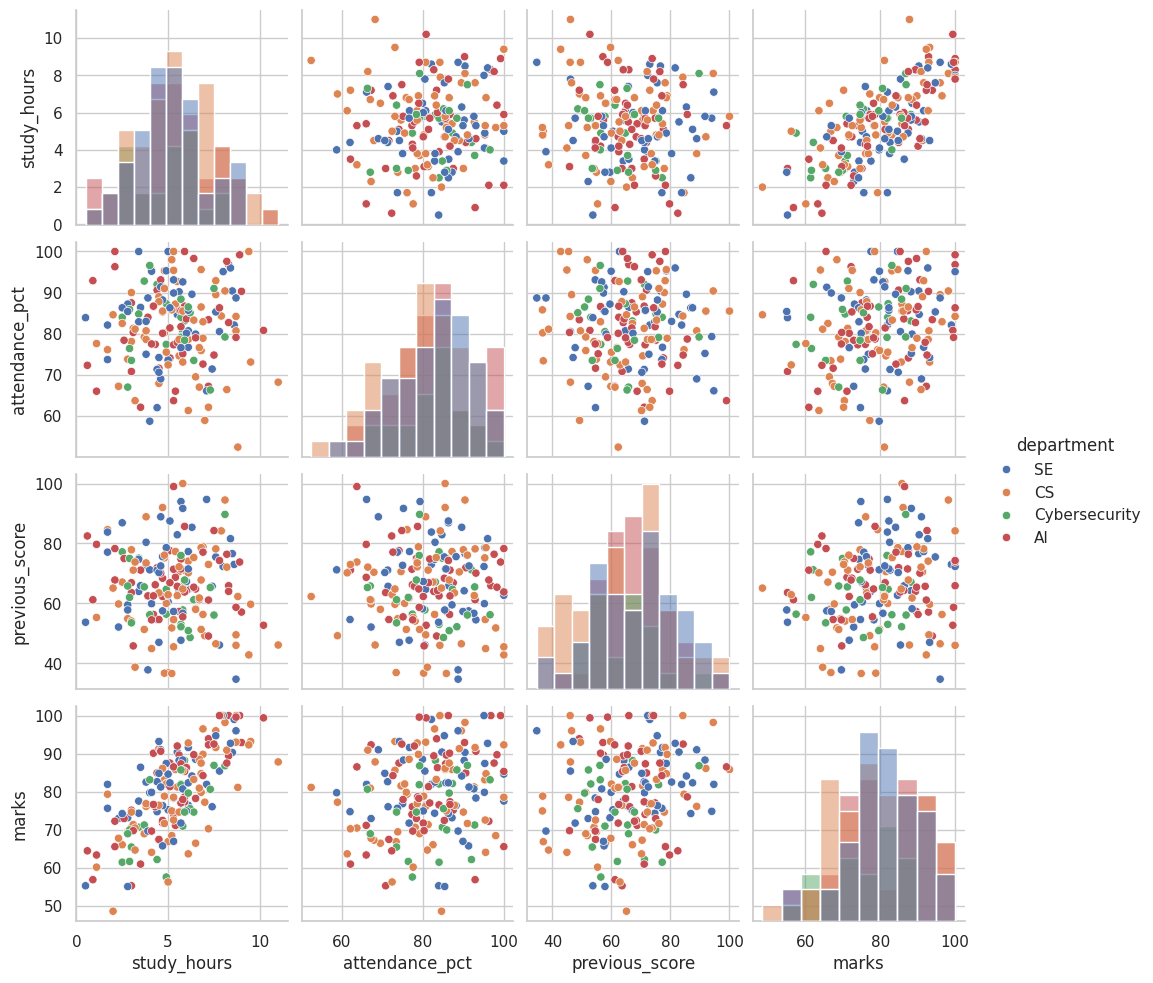

In [17]:
sns.pairplot(
    df,
    vars=[
        "study_hours",
        "attendance_pct",
        "previous_score",
        "marks"
    ],
    hue="department",
    diag_kind="hist"
)

plt.show()

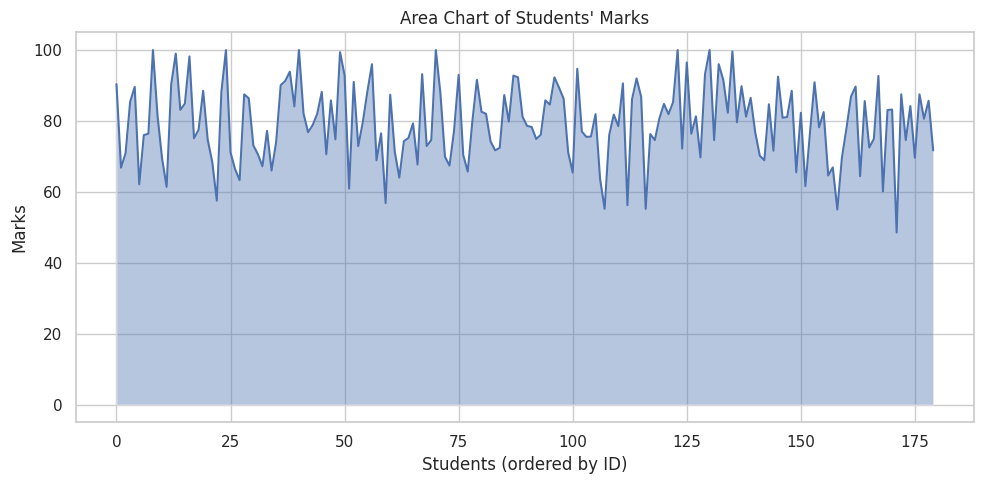

In [18]:
area_df = df.sort_values("student_id")

plt.figure(figsize=(10, 5))

plt.fill_between(
    range(len(area_df)),
    area_df["marks"].to_numpy(),
    alpha=0.4
)

plt.plot(
    range(len(area_df)),
    area_df["marks"].to_numpy()
)

plt.title("Area Chart of Students' Marks")
plt.xlabel("Students (ordered by ID)")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

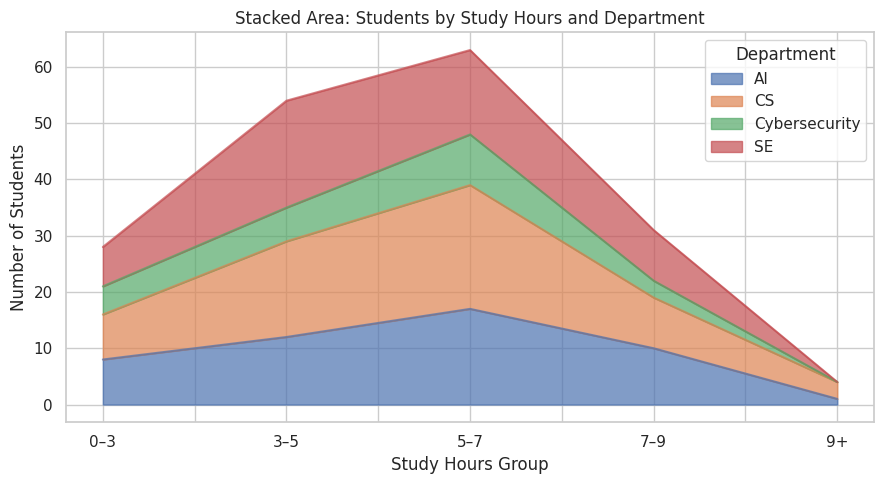

In [19]:
df["study_group"] = pd.cut(
    df["study_hours"],
    bins=[0, 3, 5, 7, 9, float("inf")],
    labels=["0–3", "3–5", "5–7", "7–9", "9+"],
    include_lowest=True
)

area_data = pd.crosstab(
    df["study_group"],
    df["department"]
)

area_data.plot(
    kind="area",
    stacked=True,
    figsize=(9, 5),
    alpha=0.7
)

plt.title("Stacked Area: Students by Study Hours and Department")
plt.xlabel("Study Hours Group")
plt.ylabel("Number of Students")
plt.legend(title="Department")
plt.tight_layout()
plt.show()

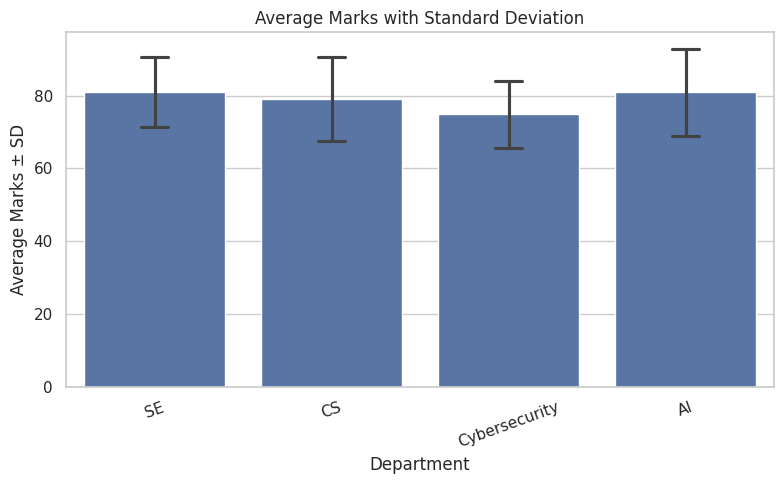

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="department",
    y="marks",
    errorbar="sd",
    capsize=0.15
)

plt.title("Average Marks with Standard Deviation")
plt.xlabel("Department")
plt.ylabel("Average Marks ± SD")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

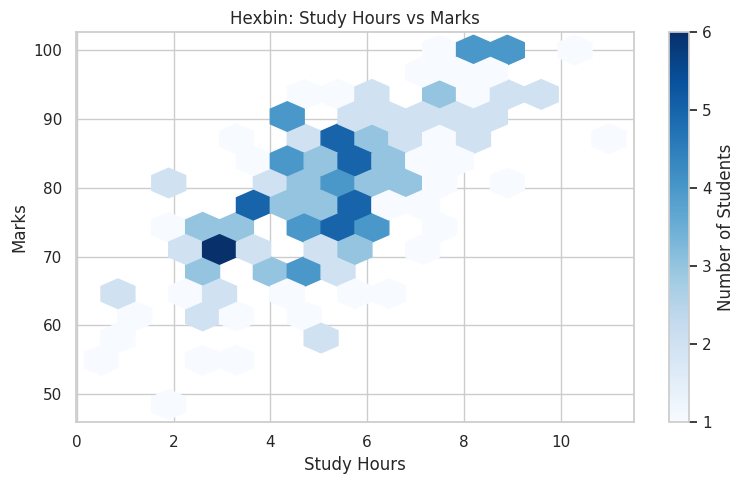

In [21]:
plt.figure(figsize=(8, 5))

plt.hexbin(
    df["study_hours"],
    df["marks"],
    gridsize=15,
    cmap="Blues",
    mincnt=1
)

plt.colorbar(label="Number of Students")

plt.title("Hexbin: Study Hours vs Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

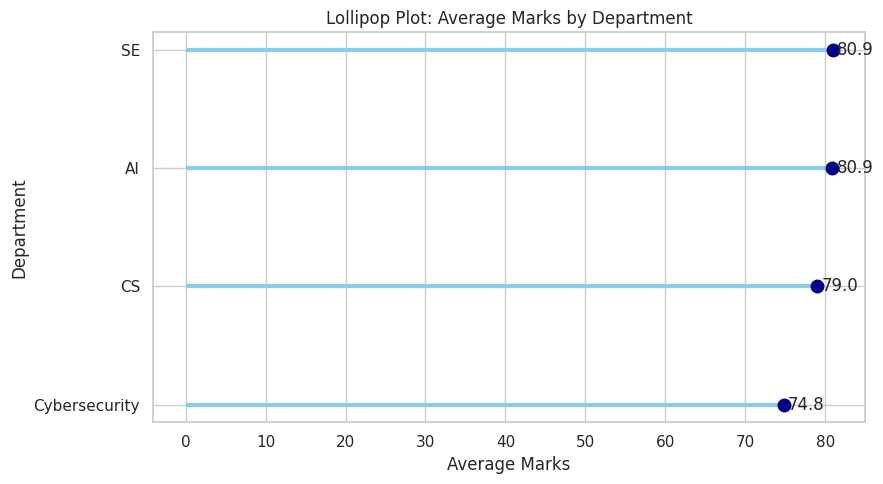

In [22]:
# Lollipop Plot: Average Marks by Department

import matplotlib.pyplot as plt

# Har department ke average marks
avg_marks = df.groupby("department")["marks"].mean().sort_values()

plt.figure(figsize=(9, 5))

plt.hlines(
    y=avg_marks.index,
    xmin=0,
    xmax=avg_marks.values,
    color="skyblue",
    linewidth=3
)

plt.plot(
    avg_marks.values,
    avg_marks.index,
    "o",
    color="darkblue",
    markersize=9
)

# Average marks ki values show karna
for department, marks in avg_marks.items():
    plt.text(marks + 0.5, department, f"{marks:.1f}", va="center")

plt.title("Lollipop Plot: Average Marks by Department")
plt.xlabel("Average Marks")
plt.ylabel("Department")
plt.tight_layout()
plt.show()